<!-- d2l:prose id=neumf-md-1 fw=all -->

# Neural Collaborative Filtering for Personalized Ranking

Clicks, purchases, and viewing events are easier to record than explicit ratings, but they pose a different statistical problem. An observed event is evidence of interest; an unobserved event may instead reflect a lack of exposure. We therefore seek a score that ranks plausible items for each user, and train it against sampled unobserved items. Neural matrix factorization (NeuMF) [@He.Liao.Zhang.ea.2017] constructs this score from two complementary feature maps: an elementwise interaction, closely related to matrix factorization, and a multilayer network applied to the user and item embeddings.

## The NeuMF model

The generalized matrix factorization (GMF) branch associates user $u$ and item $i$ with vectors $\mathbf{p}_u,\mathbf{q}_i\in\mathbb{R}^k$ and forms

$$
\begin{aligned}
\mathbf{x}_{\mathrm{GMF}} = \mathbf{p}_u \odot \mathbf{q}_i,
\end{aligned}
$$

where $\odot$ denotes elementwise multiplication. Unlike the dot product $\mathbf{p}_u^\top\mathbf{q}_i$, this operation retains all $k$ coordinatewise products for the final prediction layer.

The multilayer perceptron (MLP) branch uses separate embeddings $\mathbf{U}_u$ and $\mathbf{V}_i$. Starting from their concatenation, it computes

$$
\begin{aligned}
\mathbf{z}^{(1)} &= [\mathbf{U}_u;\mathbf{V}_i], \\
\mathbf{z}^{(\ell)} &= \alpha_\ell\!\left(\mathbf{W}^{(\ell)}\mathbf{z}^{(\ell-1)}+\mathbf{b}^{(\ell)}\right), \qquad \ell=2,\ldots,L,
\end{aligned}
$$

where $[\cdot;\cdot]$ denotes concatenation and $\alpha_\ell$ is the activation at layer $\ell$. Separate embeddings allow the two branches to represent users and items in coordinate systems suited to their respective computations.

NeuMF concatenates the two feature vectors and applies a learned linear
readout. Because BPR depends only on score differences, the implementation
returns the raw score
$$
s_{ui} = \mathbf{h}^\top[\mathbf{x}_{\mathrm{GMF}};\mathbf{z}^{(L)}].
$$
A sigmoid may convert this logit to a pointwise probability in a separately
calibrated model, but it should not be inserted before the BPR score
difference.

![NeuMF combines a GMF branch, which preserves coordinatewise products, with an MLP branch, which transforms concatenated user and item embeddings. A linear readout maps the combined features to an implicit-feedback score.](../img/rec-neumf.svg)

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
import random

<!-- d2l:prose id=neumf-md-2 fw=all -->

## Model Implementation
The following code implements the NeuMF model. It consists of a generalized matrix factorization model and an MLP with different user and item embedding vectors. The structure of the MLP is controlled with the parameter `nums_hiddens`. ReLU is used as the default activation function.

In [3]:
class NeuMF(nn.Module):
    def __init__(self, num_factors, num_users, num_items, nums_hiddens):
        super().__init__()
        self.P = nn.Embedding(num_users, num_factors)
        self.Q = nn.Embedding(num_items, num_factors)
        self.U = nn.Embedding(num_users, num_factors)
        self.V = nn.Embedding(num_items, num_factors)
        mlp_layers = []
        input_size = num_factors * 2
        for num_hiddens in nums_hiddens:
            mlp_layers.append(nn.Linear(input_size, num_hiddens))
            mlp_layers.append(nn.ReLU())
            input_size = num_hiddens
        self.mlp = nn.Sequential(*mlp_layers)
        # Output raw logits; BPRLoss applies sigmoid internally, so adding
        # a sigmoid here would compose with it and squash gradients.
        self.prediction_layer = nn.Linear(num_factors + nums_hiddens[-1], 1,
                                          bias=False)

    def forward(self, user_id, item_id):
        p_mf = self.P(user_id)
        q_mf = self.Q(item_id)
        gmf = p_mf * q_mf
        p_mlp = self.U(user_id)
        q_mlp = self.V(item_id)
        mlp = self.mlp(torch.cat([p_mlp, q_mlp], dim=1))
        con_res = torch.cat([gmf, mlp], dim=1)
        return self.prediction_layer(con_res)

<!-- d2l:prose id=neumf-md-3 fw=all -->

## Customized Dataset with Negative Sampling

For pairwise ranking, the sampling distribution is part of the objective. The
following dataset samples uniformly from the complement of each user's observed
training items. Samples are redrawn on every access, so repeated epochs compare
an observed item with different unobserved items.

This compact experiment also removes the held-out positive from the sampling
pool. That avoids assigning opposite labels to the same item, but it consults
the identity of the evaluation event during training. A strict final test would
instead tune this choice on validation users or define a proposal without using
test labels, then reserve test identities until evaluation.

In [4]:
class PRDataset(torch.utils.data.Dataset):
    def __init__(self, users, items, candidates, num_items, test_items=None):
        self.users = users
        self.items = items
        # Precompute each user's negative pool once: items the user has not
        # interacted with in train, excluding the known held-out positive.
        # This avoids a contradictory sampled label but uses evaluation identity;
        # see the protocol limitation in the surrounding text.
        all_items = set(range(num_items))
        test_items = test_items or {}
        self.neg_pool = {
            u: list(all_items - set(candidates.get(u, [])) - set(test_items.get(u, [])))
            for u in candidates}

    def __len__(self):
        return len(self.users)

    def __getitem__(self, idx):
        neg_items = self.neg_pool[int(self.users[idx])]
        indices = random.randint(0, len(neg_items) - 1)
        return self.users[idx], self.items[idx], neg_items[indices]

<!-- d2l:prose id=neumf-md-4 fw=all -->

## Evaluation on a Chronological Holdout

For each user $u$, the final observed item $g_u$ is held out and ranked within an evaluation candidate set $C_u$ that contains $g_u$ and items not observed in the training history. The candidate set is part of the protocol: ranking against every item and ranking against a sampled subset generally produce different values. The hit rate at cutoff $\ell$ is

$$
\operatorname{Hit}@\ell = \frac{1}{|\mathcal{U}|}\sum_{u\in\mathcal{U}}\mathbf{1}\{\operatorname{rank}_u(g_u)\leq\ell\}.
$$

It records whether the held-out item appears among the first $\ell$ candidates, then averages over users. The corresponding per-user AUC is the fraction of other candidates scored below the held-out item:

$$
\operatorname{AUC}=\frac{1}{|\mathcal{U}|}\sum_{u\in\mathcal{U}}\frac{1}{|C_u|-1}\sum_{j\in C_u\setminus\{g_u\}}\mathbf{1}\{\hat y_{u g_u}>\hat y_{uj}\}.
$$

The formula assigns no credit to ties; a protocol that awards half credit must say so explicitly. Hit rate and AUC answer different questions, and neither corrects for the fact that a held-out click reflects both exposure and preference.

The following function calculates the hit counts and AUC for each user.

In [5]:

def hit_and_auc(rankedlist, test_matrix, k):
    hits_k = [(idx, val) for idx, val in enumerate(rankedlist[:k])
              if val in set(test_matrix)]
    hits_all = [(idx, val) for idx, val in enumerate(rankedlist)
                if val in set(test_matrix)]
    max = len(rankedlist) - 1
    auc = 1.0 * (max - hits_all[0][0]) / max if len(hits_all) > 0 else 0
    return len(hits_k), auc

<!-- d2l:prose id=neumf-md-5 fw=all -->

Then, the overall Hit rate and AUC are calculated as follows. Note that `evaluate_ranking` rebuilds and `sorted`-ranks each user's candidate scores in a per-user Python loop for clarity; the efficient form would score all users in a batch and select the top items with a single top-k call.

In [6]:

def evaluate_ranking(net, test_input, seq, candidates, num_users, num_items,
                     devices):
    ranked_list, ranked_items, hit_rate, auc = {}, {}, [], []
    all_items = set([i for i in range(num_items)])
    for u in range(num_users):
        neg_items = list(all_items - set(candidates[int(u)]))
        user_ids, item_ids, scores = [], [], []
        [item_ids.append(i) for i in neg_items]
        [user_ids.append(u) for _ in neg_items]
        x = [torch.tensor(user_ids)]
        if seq is not None:
            x.append(seq[user_ids, :])
        x.extend([torch.tensor(item_ids)])
        test_data_iter = torch.utils.data.DataLoader(
            torch.utils.data.TensorDataset(*x), shuffle=False,
            batch_size=1024)
        for values in test_data_iter:
            values = [v.to(devices[0]) for v in values]
            # `net` returns a 1-D tensor of logits per batch; ravel
            # ensures we always extend with scalars regardless of whether
            # the model emits shape (B,) or (B, 1).
            scores.extend(net(*values).detach().cpu().numpy().ravel().tolist())
        item_scores = list(zip(item_ids, scores))
        ranked_list[u] = sorted(item_scores, key=lambda t: t[1], reverse=True)
        ranked_items[u] = [r[0] for r in ranked_list[u]]
        temp = hit_and_auc(ranked_items[u], test_input[u], 50)
        hit_rate.append(temp[0])
        auc.append(temp[1])
    return sum(hit_rate) / len(hit_rate), sum(auc) / len(auc)

<!-- d2l:prose id=neumf-md-6 fw=all -->

## Training and Evaluating the Model

The training function is defined below. We train the model in the pairwise manner.

In [7]:

def train_ranking(net, train_iter, test_iter, loss, optimizer, test_seq_iter,
                  num_users, num_items, num_epochs, devices, evaluator,
                  candidates, eval_step=1):
    timer, hit_rate, auc = d2l.Timer(), 0, 0
    animator = d2l.Animator(xlabel='epoch', xlim=[1, num_epochs], ylim=[0, 1],
                            legend=['test hit rate', 'test AUC'])
    for epoch in range(num_epochs):
        metric = d2l.Accumulator(3)
        for i, values in enumerate(train_iter):
            input_data = [v.to(devices[0]) for v in values]
            p_pos = net(*input_data[:-1])
            p_neg = net(*input_data[:-2], input_data[-1])
            ls = loss(p_pos, p_neg)
            optimizer.zero_grad()
            ls.backward()
            optimizer.step()
            # Per-batch loss only; accumulating across batches inside `l`
            # turned the printed train-loss into a quadratic sum.
            metric.add(ls.item(), values[0].shape[0], values[0].numel())
            timer.stop()
        with torch.no_grad():
            if (epoch + 1) % eval_step == 0:
                hit_rate, auc = evaluator(net, test_iter, test_seq_iter,
                                          candidates, num_users, num_items,
                                          devices)
                animator.add(epoch + 1, (hit_rate, auc))
    print(f'train loss {metric[0] / metric[1]:.3f}, '
          f'test hit rate {float(hit_rate):.3f}, test AUC {float(auc):.3f}')
    print(f'{metric[2] * num_epochs / timer.sum():.1f} examples/sec '
          f'on {str(devices)}')

<!-- d2l:prose id=neumf-md-7 fw=all -->

Now, we can load the MovieLens 100k dataset and train the model. Since there are only ratings in the MovieLens dataset, with some losses of accuracy, we binarize these ratings to zeros and ones. If a user rated an item, we consider the implicit feedback as one, otherwise as zero. The action of rating an item can be treated as a form of providing implicit feedback.  Here, we split the dataset in the `seq-aware` mode where users' latest interacted items are left out for test.

In [8]:
batch_size = 1024
df, num_users, num_items = d2l.read_data_ml100k()
train_data, test_data = d2l.split_data_ml100k(df, num_users, num_items,
                                              'seq-aware')
users_train, items_train, ratings_train, candidates = d2l.load_data_ml100k(
    train_data, num_users, num_items, feedback="implicit")
users_test, items_test, ratings_test, test_iter = d2l.load_data_ml100k(
    test_data, num_users, num_items, feedback="implicit")
train_iter = torch.utils.data.DataLoader(
    PRDataset(users_train, items_train, candidates, num_items,
              test_items=test_iter), batch_size,
    True, num_workers=d2l.get_dataloader_workers())

<!-- d2l:prose id=neumf-md-8 fw=all -->

We then create and initialize the model. We use a three-layer MLP with constant hidden size 10.

In [9]:
devices = d2l.try_all_gpus()
net = NeuMF(10, num_users, num_items, nums_hiddens=[10, 10, 10])
def init_weights(m):
    if type(m) == nn.Linear or type(m) == nn.Embedding:
        nn.init.normal_(m.weight, std=0.01)
net.apply(init_weights)
net = net.to(devices[0])

<!-- d2l:prose id=neumf-md-9 fw=all -->

The following code trains the model.

train loss 0.151, test hit rate 0.345, test AUC 0.883
6.5 examples/sec on [device(type='cuda', index=0)]


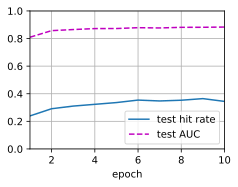

In [10]:
lr, num_epochs, wd = 0.01, 10, 1e-5
loss = d2l.BPRLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=wd)
train_ranking(net, train_iter, test_iter, loss, optimizer, None, num_users,
              num_items, num_epochs, devices, evaluate_ranking, candidates)

<!-- d2l:prose id=neumf-md-10 fw=all -->

## Summary

* NeuMF combines coordinatewise latent-factor interactions with nonlinear features computed from concatenated user and item embeddings.
* The two branches use separate embeddings and are joined only at the prediction layer.

## Exercises

1. Score every candidate item by its number of training interactions, with
   the same scores for every user, and evaluate this popularity ranking with
   `evaluate_ranking` by wrapping it in a module whose forward pass ignores
   the user. Report its hit rate and AUC next to those of NeuMF. How much of
   NeuMF's AUC above 0.5 does popularity alone account for?
1. Show that the GMF branch alone, with readout $\mathbf h$, computes
   $\mathbf p_u^\top\operatorname{diag}(\mathbf h)\,\mathbf q_i$ and therefore
   represents exactly the scores of a dot-product model with $k$ factors.
   Then show that if the MLP branch has no activation functions, its
   contribution to the score has the form $f(u)+g(i)$, and that $f(u)$
   cancels from every score difference that BPR uses. What does the MLP
   branch need in order to model an interaction between user and item?
1. Train NeuMF with `HingeLossbRec` in place of `BPRLoss`, keeping the other
   settings, and report the hit rate and AUC. At the end of training, measure
   the fraction of training triples whose hinge loss is zero, and explain
   what that fraction means for the gradient the remaining epochs receive.
1. Train the GMF branch alone, the MLP branch alone, and NeuMF with
   `num_factors=10` and the optimizer settings above, and report the hit rate
   and AUC of each. Count the parameters of each model. Which part of NeuMF
   holds most of its parameters, and does the ablation suggest that the MLP
   branch adds accuracy?
1. `evaluate_ranking` ranks the held-out item against all unobserved items.
   The evaluation of [@He.Liao.Zhang.ea.2017] instead ranks it against
   100 sampled unobserved items. Implement the sampled protocol and report
   the hit rate at cutoff 10 under both protocols for NeuMF and for the
   popularity ranking of the first problem. Does the ordering of the two
   models change? Explain why a metric computed on sampled candidates need not
   preserve the ordering of the same metric on the full candidate set.

<!-- d2l:prose id=neumf-md-11 fw=pytorch -->

[Discussions](https://d2l.discourse.group/t/403)